# RQ1 Chunking Evaluation (Retrieval-Only)

This notebook executes **Research Question 1** only:

- 3 chunking strategies (`fixed`, `structure_aware`, `semantic`)
- 3 chunk sizes (`256`, `512`, `1024`)
- 4 retrieval methods (`dense`, `sparse`, `hybrid_rrf`, `hybrid_rerank`)

Total: **36 configurations**.

The notebook is intentionally structured in commented sections so each stage is transparent and reproducible.

In [1]:
# ------------------------------------------------------------
# 1) Environment and imports
# ------------------------------------------------------------
# This section validates that the notebook is executed from project root
# context and that required packages are importable.

import sys
from pathlib import Path

# Add project root so `rag` is importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt

from rag.config.settings import RQ1_RESULTS_DIR, build_rq1_experiment_grid
from rag.pipeline.rq1_runner import RQ1PipelineRunner

print(f'Project root: {PROJECT_ROOT}')
print(f'RQ1 result directory: {RQ1_RESULTS_DIR}')

Project root: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ1 result directory: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq1


In [2]:
# ------------------------------------------------------------
# 2) Build and inspect the 36-configuration experiment grid
# ------------------------------------------------------------
# This makes the factorial design explicit before execution.

grid = build_rq1_experiment_grid()
print(f'Total configs: {len(grid)}')

grid_df = pd.DataFrame([
    {
        'config_id': c.config_id,
        'chunk_strategy': c.chunk_strategy,
        'chunk_size': c.chunk_size,
        'retrieval_method': c.retrieval_method,
    }
    for c in grid
])

grid_df.head(36)

Total configs: 36


,config_id,chunk_strategy,chunk_size,retrieval_method
0,fixed_256_dense,fixed,256,dense
1,fixed_256_sparse,fixed,256,sparse
2,fixed_256_hybrid_rrf,fixed,256,hybrid_rrf
3,fixed_256_hybrid_rerank,fixed,256,hybrid_rerank
4,fixed_512_dense,fixed,512,dense
5,fixed_512_sparse,fixed,512,sparse
6,fixed_512_hybrid_rrf,fixed,512,hybrid_rrf
7,fixed_512_hybrid_rerank,fixed,512,hybrid_rerank
8,fixed_1024_dense,fixed,1024,dense
9,fixed_1024_sparse,fixed,1024,sparse


In [3]:
# ------------------------------------------------------------
# 3) Execute RQ1 evaluation
# ------------------------------------------------------------
# Set DRY_RUN to False to execute all 36 configurations.
# Keep it True for smoke-testing notebook flow first.

DRY_RUN = False
runner = RQ1PipelineRunner(dry_run=DRY_RUN)
summary = runner.run()
summary

/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_256> contains 33391 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_512> contains 30470 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulatio

Running config: fixed_256_dense
  -> completed: recall@15 = 0.5206
Running config: fixed_256_sparse
  -> completed: recall@15 = 0.7559
Running config: fixed_256_hybrid_rrf
  -> completed: recall@15 = 0.6853
Running config: fixed_256_hybrid_rerank


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  -> completed: recall@15 = 0.6706
Running config: fixed_512_dense
  -> completed: recall@15 = 0.5882
Running config: fixed_512_sparse
  -> completed: recall@15 = 0.8843
Running config: fixed_512_hybrid_rrf
  -> completed: recall@15 = 0.7853
Running config: fixed_512_hybrid_rerank
  -> completed: recall@15 = 0.7657
Running config: fixed_1024_dense
  -> completed: recall@15 = 0.6980
Running config: fixed_1024_sparse
  -> completed: recall@15 = 0.9461
Running config: fixed_1024_hybrid_rrf
  -> completed: recall@15 = 0.8657
Running config: fixed_1024_hybrid_rerank
  -> completed: recall@15 = 0.8431
Running config: structure_aware_256_dense
  -> completed: recall@15 = 0.4725
Running config: structure_aware_256_sparse
  -> completed: recall@15 = 0.7686
Running config: structure_aware_256_hybrid_rrf
  -> completed: recall@15 = 0.6716
Running config: structure_aware_256_hybrid_rerank
  -> completed: recall@15 = 0.6353
Running config: structure_aware_512_dense
  -> completed: recall@15 = 0.565

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:77: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Current collection contains 33391 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client.upsert(collection_name=collection_name, points=points, wait=True)


  -> completed: recall@15 = 0.1775
Running config: semantic_256_sparse
  -> completed: recall@15 = 0.4667
Running config: semantic_256_hybrid_rrf
  -> completed: recall@15 = 0.4010
Running config: semantic_256_hybrid_rerank
  -> completed: recall@15 = 0.3775
Running config: semantic_512_dense
  -> completed: recall@15 = 0.1912
Running config: semantic_512_sparse
  -> completed: recall@15 = 0.5167
Running config: semantic_512_hybrid_rrf
  -> completed: recall@15 = 0.4422
Running config: semantic_512_hybrid_rerank
  -> completed: recall@15 = 0.4127
Running config: semantic_1024_dense
  -> completed: recall@15 = 0.2010
Running config: semantic_1024_sparse
  -> completed: recall@15 = 0.5078
Running config: semantic_1024_hybrid_rrf
  -> completed: recall@15 = 0.4627
Running config: semantic_1024_hybrid_rerank
  -> completed: recall@15 = 0.4382


{'winner': 'fixed_1024_sparse',
 'winner_metrics': {'recall@5': 0.8480392156862745,
  'recall@10': 0.9225490196078431,
  'recall@15': 0.946078431372549,
  'precision@5': 0.6776470588235294,
  'precision@10': 0.6176470588235294,
  'precision@15': 0.5874509803921568,
  'ndcg@10': 0.7930582082736977,
  'mrr@10': 0.8648179271708684,
  'budgeted_recall@4096': 0.8362745098039216},
 'evaluated_configs': 36}

In [4]:
# ------------------------------------------------------------
# 4) Load persisted results
# ------------------------------------------------------------
# The runner writes a CSV and JSON artifact for transparency.

results_csv = RQ1_RESULTS_DIR / 'rq1_config_results.csv'
results_json = RQ1_RESULTS_DIR / 'rq1_config_results.json'

df = pd.read_csv(results_csv)
print(f'Loaded {len(df)} rows from {results_csv.name}')
df.sort_values('recall@15', ascending=False).head(10)

Loaded 36 rows from rq1_config_results.csv


,config_id,chunk_strategy,chunk_size,retrieval_method,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
0,fixed_1024_sparse,fixed,1024,sparse,0.848039,0.922549,0.946078,0.677647,0.617647,0.587451,0.793058,0.864818,0.836275
1,structure_aware_1024_sparse,structure_aware,1024,sparse,0.766667,0.846078,0.910784,0.548235,0.476471,0.441569,0.684504,0.779542,0.802941
2,fixed_512_sparse,fixed,512,sparse,0.732353,0.844118,0.884314,0.552941,0.487059,0.443922,0.703083,0.785826,0.816667
3,structure_aware_512_sparse,structure_aware,512,sparse,0.711765,0.826471,0.870588,0.503529,0.418824,0.363922,0.671940,0.735994,0.820588
4,fixed_1024_hybrid_rrf,fixed,1024,hybrid_rrf,0.728431,0.805882,0.865686,0.651765,0.597647,0.578824,0.739485,0.779440,0.700000
5,fixed_1024_hybrid_rerank,fixed,1024,hybrid_rerank,0.740196,0.804902,0.843137,0.651765,0.598824,0.574118,0.758291,0.781863,0.705882
6,structure_aware_1024_hybrid_rrf,structure_aware,1024,hybrid_rrf,0.649020,0.703922,0.795098,0.512941,0.470588,0.435294,0.628067,0.698445,0.656863
7,structure_aware_512_hybrid_rrf,structure_aware,512,hybrid_rrf,0.632353,0.713725,0.790196,0.451765,0.371765,0.327059,0.605368,0.634216,0.684314
8,fixed_512_hybrid_rrf,fixed,512,hybrid_rrf,0.613725,0.712745,0.785294,0.505882,0.438824,0.400000,0.624206,0.682283,0.667647
9,structure_aware_256_sparse,structure_aware,256,sparse,0.585294,0.717647,0.768627,0.404706,0.308235,0.258824,0.607874,0.633492,0.762745


,chunk_strategy,recall@15
0,fixed,0.750735
2,structure_aware,0.712173
1,semantic,0.382925


,chunk_size,recall@15
2,1024,0.667484
1,512,0.628105
0,256,0.550245


,retrieval_method,recall@15
3,sparse,0.736383
2,hybrid_rrf,0.655447
1,hybrid_rerank,0.624837
0,dense,0.444444


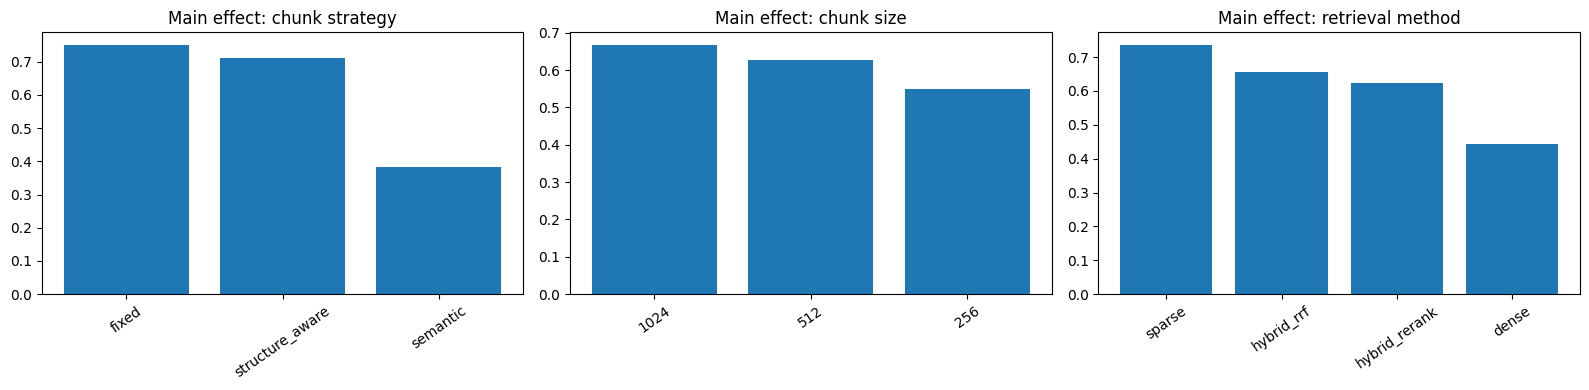

In [5]:
# ------------------------------------------------------------
# 5) Main effects (RQ1 analysis requirement)
# ------------------------------------------------------------
# We average Recall@15 over the other factors to inspect each main effect.

main_strategy = df.groupby('chunk_strategy', as_index=False)['recall@15'].mean().sort_values('recall@15', ascending=False)
main_size = df.groupby('chunk_size', as_index=False)['recall@15'].mean().sort_values('recall@15', ascending=False)
main_retrieval = df.groupby('retrieval_method', as_index=False)['recall@15'].mean().sort_values('recall@15', ascending=False)

display(main_strategy)
display(main_size)
display(main_retrieval)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(main_strategy['chunk_strategy'], main_strategy['recall@15'])
axes[0].set_title('Main effect: chunk strategy')
axes[1].bar(main_size['chunk_size'].astype(str), main_size['recall@15'])
axes[1].set_title('Main effect: chunk size')
axes[2].bar(main_retrieval['retrieval_method'], main_retrieval['recall@15'])
axes[2].set_title('Main effect: retrieval method')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

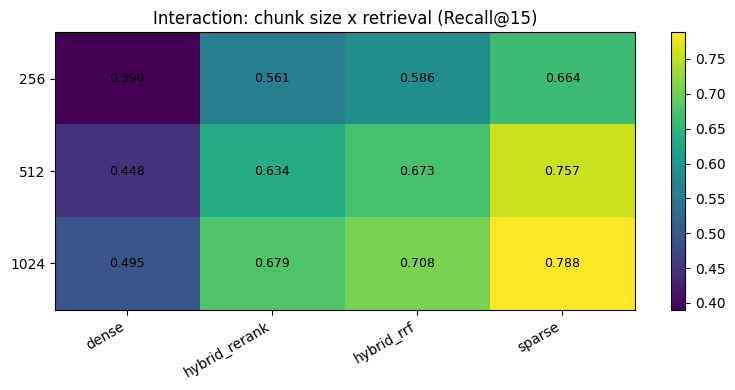

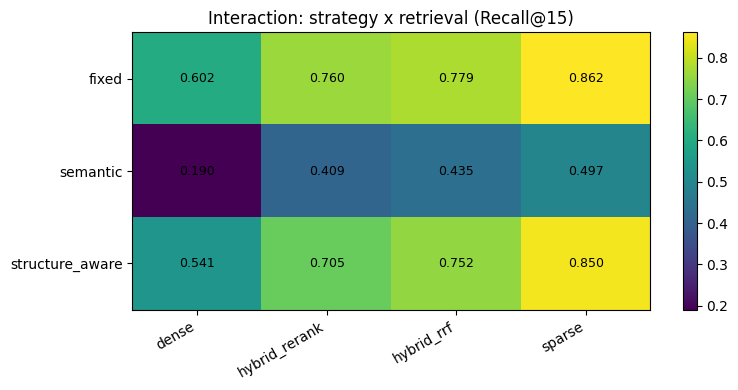

In [6]:
# ------------------------------------------------------------
# 6) Interaction views (heatmaps)
# ------------------------------------------------------------
# RQ1 requires attention to interactions such as chunk size x retrieval.

pivot_size_method = df.pivot_table(
    values='recall@15',
    index='chunk_size',
    columns='retrieval_method',
    aggfunc='mean',
)

pivot_strategy_method = df.pivot_table(
    values='recall@15',
    index='chunk_strategy',
    columns='retrieval_method',
    aggfunc='mean',
)

def plot_heatmap(pivot_df, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    im = ax.imshow(pivot_df.values, aspect='auto')
    ax.set_xticks(range(len(pivot_df.columns)))
    ax.set_xticklabels(list(pivot_df.columns), rotation=30, ha='right')
    ax.set_yticks(range(len(pivot_df.index)))
    ax.set_yticklabels(list(pivot_df.index))
    ax.set_title(title)
    for i in range(pivot_df.shape[0]):
        for j in range(pivot_df.shape[1]):
            ax.text(j, i, f"{pivot_df.values[i, j]:.3f}", ha='center', va='center', fontsize=9)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

plot_heatmap(pivot_size_method, 'Interaction: chunk size x retrieval (Recall@15)')
plot_heatmap(pivot_strategy_method, 'Interaction: strategy x retrieval (Recall@15)')

In [7]:
# ------------------------------------------------------------
# 7) Robustness and winner selection
# ------------------------------------------------------------
# Primary criterion: Recall@15
# Robustness check: Budgeted Recall@4096 tokens

rank_primary = df[['config_id', 'recall@15']].sort_values('recall@15', ascending=False).reset_index(drop=True)
rank_budget = df[['config_id', 'budgeted_recall@4096']].sort_values('budgeted_recall@4096', ascending=False).reset_index(drop=True)

winner_primary = rank_primary.iloc[0]
winner_budget = rank_budget.iloc[0]

print('Winner by Recall@15:', winner_primary.to_dict())
print('Winner by Budgeted Recall@4096:', winner_budget.to_dict())

comparison = rank_primary.merge(rank_budget, on='config_id', suffixes=('_primary_rank_source', '_budget_rank_source'))
comparison['primary_rank'] = comparison['recall@15'].rank(ascending=False, method='min')
comparison['budget_rank'] = comparison['budgeted_recall@4096'].rank(ascending=False, method='min')
comparison['rank_delta'] = (comparison['primary_rank'] - comparison['budget_rank']).abs()
comparison.sort_values('rank_delta').head(15)

Winner by Recall@15: {'config_id': 'fixed_1024_sparse', 'recall@15': 0.946078431372549}
Winner by Budgeted Recall@4096: {'config_id': 'fixed_1024_sparse', 'budgeted_recall@4096': 0.8362745098039216}


,config_id,recall@15,budgeted_recall@4096,primary_rank,budget_rank,rank_delta
0,fixed_1024_sparse,0.946078,0.836275,1.0,1.0,0.0
33,semantic_1024_dense,0.200980,0.200980,34.0,34.0,0.0
32,semantic_256_hybrid_rerank,0.377451,0.377451,33.0,33.0,0.0
31,semantic_256_hybrid_rrf,0.400980,0.400980,32.0,32.0,0.0
30,semantic_512_hybrid_rerank,0.412745,0.412745,31.0,31.0,0.0
29,semantic_1024_hybrid_rerank,0.438235,0.438235,30.0,30.0,0.0
28,semantic_512_hybrid_rrf,0.442157,0.442157,29.0,29.0,0.0
27,semantic_1024_hybrid_rrf,0.462745,0.462745,28.0,28.0,0.0
26,semantic_256_sparse,0.466667,0.466667,27.0,27.0,0.0
25,structure_aware_256_dense,0.472549,0.472549,26.0,26.0,0.0


In [8]:
# ------------------------------------------------------------
# 8) Optional deep-dive outputs (per-ESRS and chunk stats)
# ------------------------------------------------------------
# This cell reads winner details and chunk-stat files written by the runner.

winner_path = RQ1_RESULTS_DIR / 'rq1_winner.json'
winner_payload = json.loads(winner_path.read_text(encoding='utf-8'))

print('Winner config:', winner_payload['config_id'])
print('Winner metrics:')
display(pd.DataFrame([winner_payload['metrics']]))

print('Per-ESRS breakdown (winner):')
per_std_df = pd.DataFrame(winner_payload['per_standard_metrics']).T
per_std_df = per_std_df.sort_values('recall@15', ascending=False)
display(per_std_df)

chunk_stats_files = sorted(RQ1_RESULTS_DIR.glob('chunk_stats_*.json'))
chunk_stats_rows = [json.loads(p.read_text(encoding='utf-8')) | {'file': p.name} for p in chunk_stats_files]
if chunk_stats_rows:
    display(pd.DataFrame(chunk_stats_rows).sort_values('total_chunks', ascending=False))

Winner config: fixed_1024_sparse
Winner metrics:


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
0,0.848039,0.922549,0.946078,0.677647,0.617647,0.587451,0.793058,0.864818,0.836275


Per-ESRS breakdown (winner):


,recall@5,recall@10,recall@15,precision@5,precision@10,precision@15,ndcg@10,mrr@10,budgeted_recall@4096
ESRS 2,0.892157,0.970588,0.970588,0.623529,0.600000,0.560784,0.768305,0.782913,0.892157
ESRS 1,0.862745,0.960784,0.960784,0.905882,0.882353,0.854902,0.960967,1.000000,0.862745
ESRS G1,0.877451,0.946078,0.946078,0.670588,0.611765,0.603922,0.824382,1.000000,0.877451
ESRS E1,0.813725,0.882353,0.941176,0.670588,0.652941,0.643137,0.746854,0.823529,0.813725
ESRS S1,0.794118,0.852941,0.911765,0.517647,0.341176,0.274510,0.664784,0.717647,0.735294


,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens,file
4,33467,81.934742,83.693624,1,258,chunk_stats_semantic_256.json
5,30546,88.510869,127.522362,1,514,chunk_stats_semantic_512.json
3,29412,90.737046,174.868022,1,1025,chunk_stats_semantic_1024.json
7,13481,214.625621,73.828682,2,258,chunk_stats_structure_aware_256.json
1,11582,255.937058,4.457372,58,259,chunk_stats_fixed_256.json
8,8032,354.098481,184.108928,2,514,chunk_stats_structure_aware_512.json
2,5794,511.471177,13.190498,80,515,chunk_stats_fixed_512.json
6,5581,498.356925,389.482537,2,1026,chunk_stats_structure_aware_1024.json
0,2902,1020.943832,46.237550,140,1027,chunk_stats_fixed_1024.json
